# Пайбук: робот Школы мобильных роботов

**Блок 1 — езда по линии туда-обратно на Arduino.** Innopolis Robotics Society, октябрь 2026.

Здесь описан каждый компонент робота: что это, зачем он нужен, как его подключить и как проверить, что он работает. Код для Arduino приведён в блоках `cpp` — копируйте его в Arduino IDE. Ячейки на Python можно запускать прямо в блокноте: они считают параметры робота.

### Содержание

1. [Безопасность](#1.-Безопасность)
2. [Устройство робота](#2.-Устройство-робота)
3. [Питание](#3.-Питание)
4. [Контроллер Iskra Uno](#4.-Контроллер-Iskra-Uno)
5. [Troyka Shield](#5.-Troyka-Shield)
6. [Motor Shield Plus](#6.-Motor-Shield-Plus)
7. [Моторы с энкодерами](#7.-Моторы-с-энкодерами)
8. [Захват и сервоприводы](#8.-Захват-и-сервоприводы)
9. [Датчики линии](#9.-Датчики-линии)
10. [Датчики расстояния](#10.-Датчики-расстояния)
11. [Карта пинов](#11.-Карта-пинов)
12. [Первое включение](#12.-Первое-включение)
13. [Неисправности](#13.-Неисправности)

## 1. Безопасность

Прочитайте этот раздел до того, как включать робота.

На роботе стоят три литий-ионных аккумулятора 18650. Ошибка с ними — это не сгоревшая плата, а горящий аккумулятор.

- **Не замыкайте плюс и минус.** Даже на секунду: ток короткого замыкания — десятки ампер, провод раскаляется. Не кладите робота на металл, не оставляйте оголённые провода.
- **Соблюдайте полярность.** Красный провод — плюс, чёрный — минус. Перепутанная полярность выводит из строя DC-DC и сервы.
- **Аккумуляторы ставьте по маркировке кассеты.** Один перевёрнутый элемент — и напряжение блока неправильное, а элемент греется.
- **Не разряжайте блок ниже ~9,6 В** (3,2 В на элемент). У кассеты нет защиты от переразряда. Робот заметно замедлился — пора менять аккумуляторы.
- **Заряжайте только зарядкой из лаборатории** и только под присмотром.
- **Элемент горячий, вздулся или помят** — выньте его и отдайте руководителю. Не пользуйтесь им.
- **Перекоммутация — только при выключенном питании** и отсоединённом USB. Уходите от робота — выключатель в «выкл».

## 2. Устройство робота

Робот — двухъярусная платформа с дифференциальным приводом: два ведущих колеса по бокам и пассивная опора сзади. Спереди стоит захват на двух сервоприводах, по бокам от него — два датчика линии.

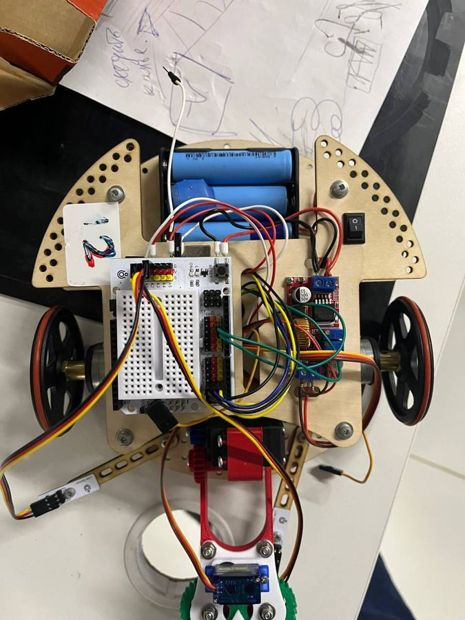

*Вид сверху. Захват — внизу кадра (это перед робота), батарейный блок — вверху (зад).*

### Компоновка

| Узел | Где стоит | Что важно знать |
| --- | --- | --- |
| Нижняя дека | Круглая фанерная пластина | Перфорация — посадочные места под крепёж. На ней всё тяжёлое: моторы, аккумуляторы, захват |
| Мотор-редукторы | Под нижней декой, на кронштейнах, по бокам | Ось колёс проходит примерно через середину робота |
| Колёса | По бокам, 72 мм | Резиновое кольцо работает как шина. Латунная ступица держится на валу винтом |
| Опора | Сзади, под батарейным блоком | Пассивная, только держит робота горизонтально |
| Батарейный блок 3×18650 | Сзади на нижней деке | Уравновешивает захват спереди |
| Верхняя дека | На латунных стойках над нижней | Электроника: стек плат, DC-DC, выключатель |
| Стек плат | В центре верхней деки | Iskra Uno, Motor Shield Plus, сверху Troyka Shield с макеткой |
| DC-DC | Справа на верхней деке | Питает только сервы |
| Выключатель | На правом «крыле» верхней деки | Разрывает всё питание от батареи |
| Захват | Спереди | Поднимается и опускается, губки сжимаются и разжимаются |
| Датчики линии | На регулируемых планках слева и справа от захвата | Положение и расстояние между ними можно менять |

### Ходовая часть

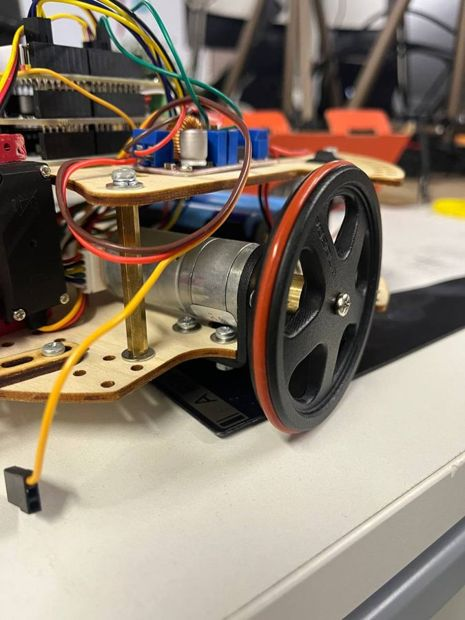

- **Дифференциальный привод.** Руля нет. Робот поворачивает, крутя колёса с разной скоростью; в разные стороны — разворачивается на месте вокруг центра между колёсами.
- **Колесо держится на валу винтом в ступице.** Если винт ослаб, колесо проскальзывает: робот едет криво, а энкодер считает обороты, которых не было. Проверяйте затяжку.
- **Резиновое кольцо** даёт сцепление. Слетевшее или грязное кольцо — робот буксует на развороте.
- **Опора сзади** должна свободно скользить или катиться и не приподнимать ведущие колёса.

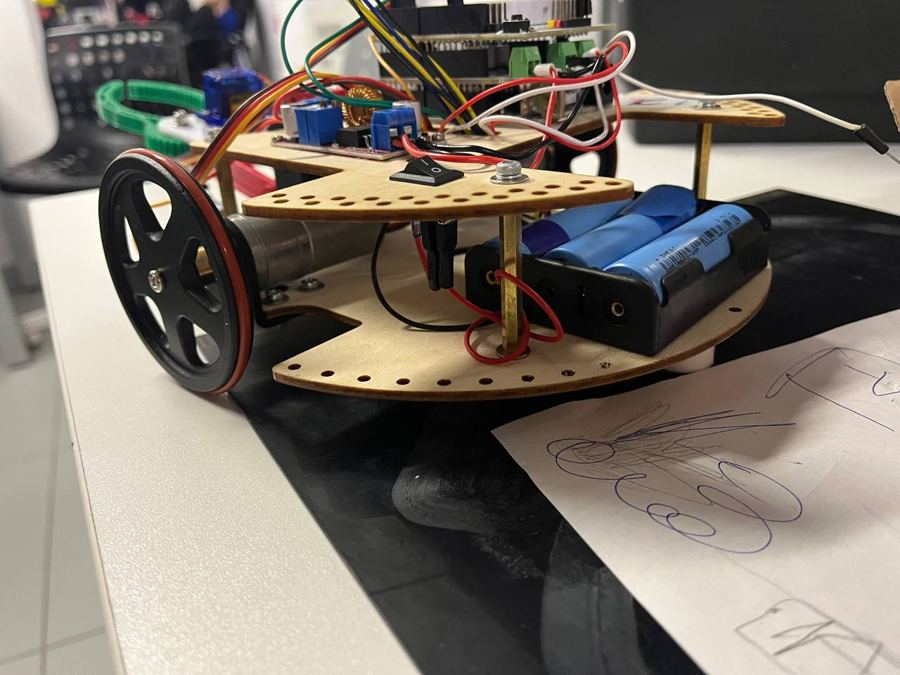

### Захват

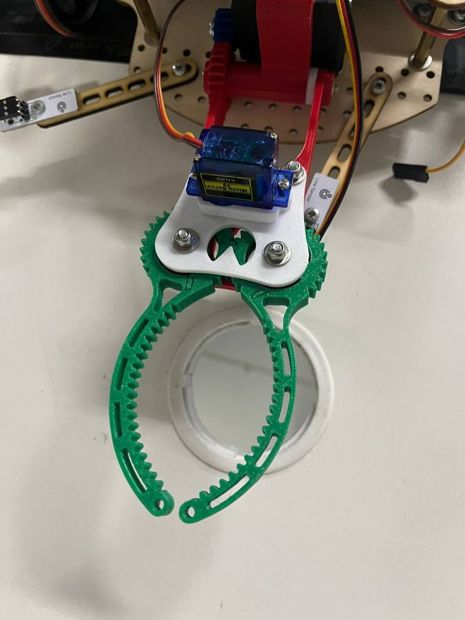

Захват состоит из двух узлов.

**Подъём — сервопривод MG996R.** Он стоит вертикально в красном кронштейне у переднего края нижней деки. Через пару шестерён он поворачивает красную стрелу вверх и вниз. Из-за шестерён угол стрелы не равен углу сервы, поэтому рабочие углы подбираются калибровкой (раздел 8).

**Сжатие — сервопривод SG90.** Он стоит на белой пластине на конце стрелы. Шестерня на его валу входит в зубчатые венцы двух зелёных губок, и губки поворачиваются навстречу друг другу симметрично. Изогнутая форма губок рассчитана на круглые предметы: стакан, банку, кольцо.

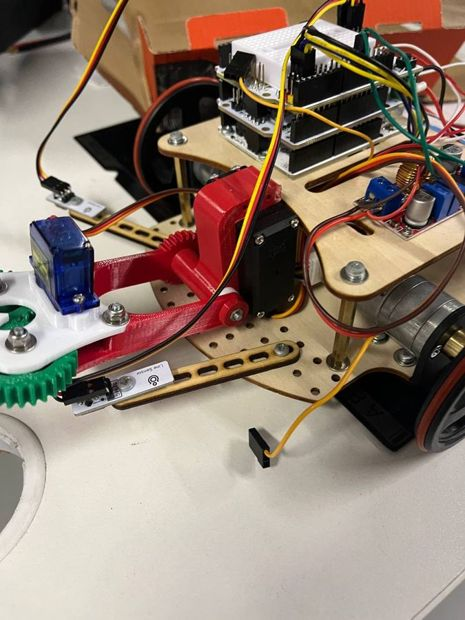

Что из этого следует для управления:

- **Захват выступает далеко вперёд от оси колёс.** При развороте на месте губки описывают большую окружность. Перед разворотом поднимайте захват и проверяйте, что рядом ничего нет.
- **Опущенная стрела с грузом — самая тяжёлая нагрузка для MG996R.** Не держите её долго в промежуточном положении под нагрузкой.
- **SG90 слабая, шестерни пластиковые.** Губки сжимаются до касания предмета, не сильнее.

### Схема: питание и сигналы

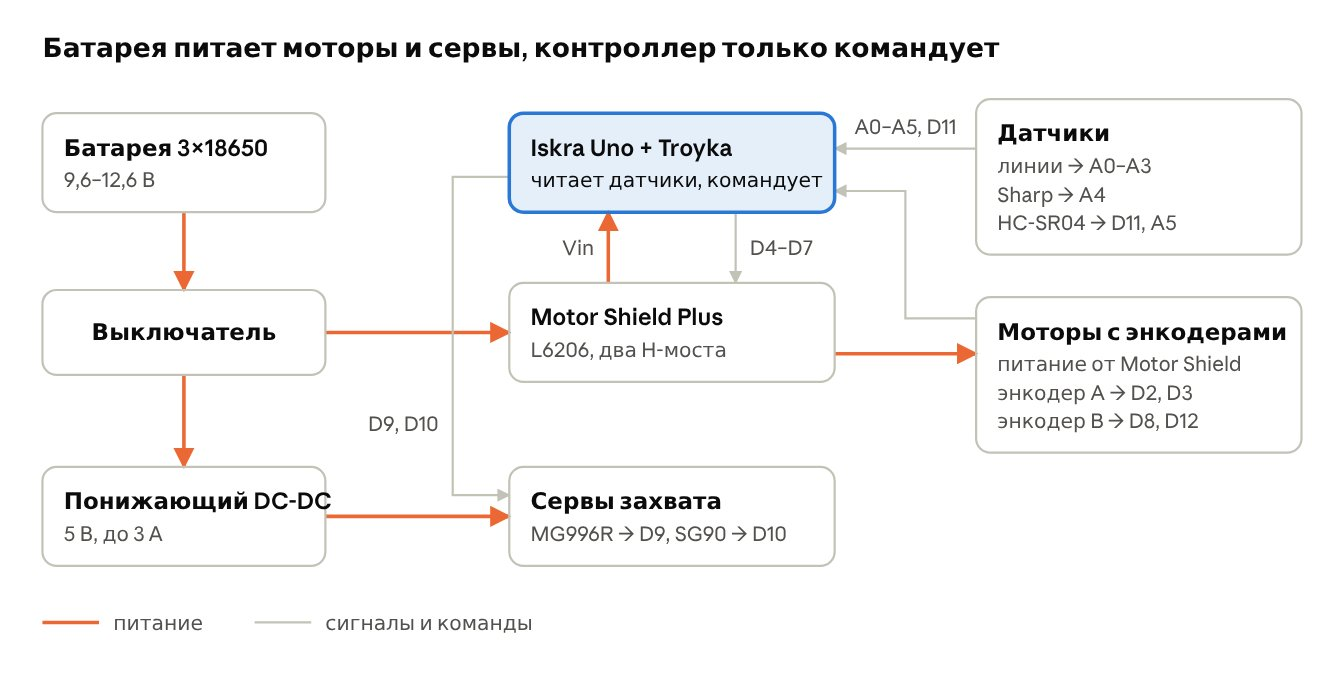

У робота две независимые ветки питания, и ни одна не идёт через пины контроллера. Контроллер читает датчики и энкодеры и отдаёт команды, а ток моторам и сервам дают Motor Shield и DC-DC.

### Первичная коммутация

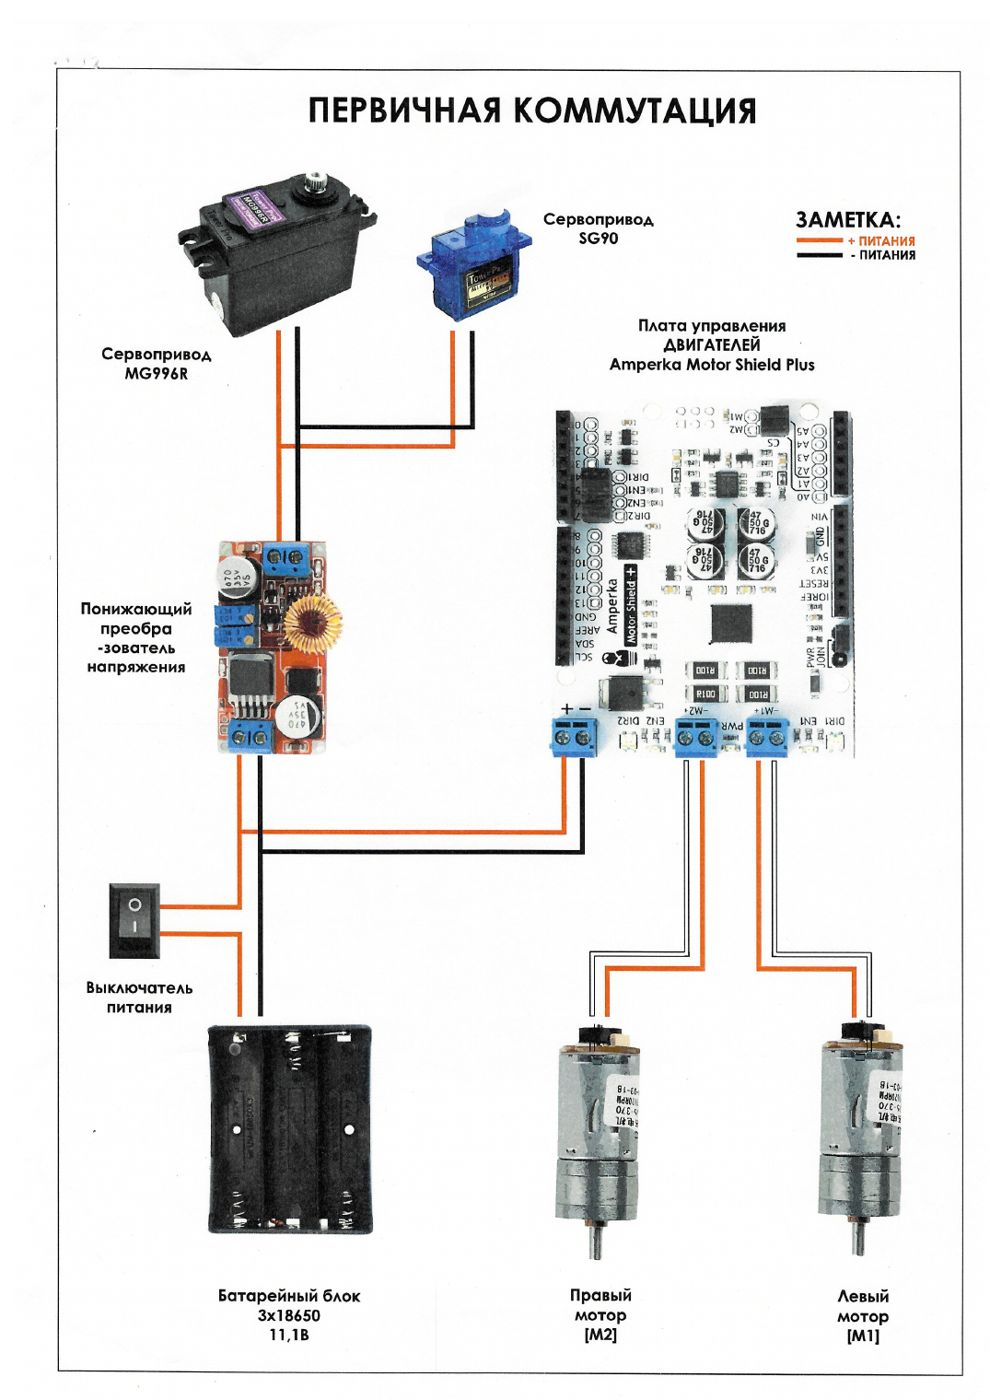

Красные (оранжевые) линии — плюс питания, чёрные — минус. Левый мотор подключается к каналу M1, правый — к M2.

## 3. Питание

От батарейного блока через выключатель идут две ветки. **Силовая** — на клеммник Motor Shield: оттуда питаются моторы и контроллер. **Вторая** — через понижающий DC-DC на 5 В к сервам.

### Батарейный блок 3×18650

Три аккумулятора соединены последовательно, напряжения складываются.

| Состояние | На элемент, В | На блок, В |
| --- | --- | --- |
| Полностью заряжен | 4,2 | 12,6 |
| Номинал | 3,7 | 11,1 |
| Пора заряжать | 3,2 | 9,6 |

Скорость моторов зависит от напряжения. Коэффициенты, подобранные на свежих аккумуляторах, на посаженных работают иначе — поэтому дальше пригодятся энкодеры.

### Motor Shield и питание контроллера

Контроллер питается через **джампер объединения питания** на Motor Shield. Джампер соединяет силовое питание с пином Vin, а стабилизатор на плате контроллера делает из него 5 В. Джампер снят — контроллер работает только от USB.

Vin рассчитан на 7,5–12 В. Свежезаряженный блок (12,6 В) чуть выше, стабилизатор будет тёплым — это нормально. А вот питать от контроллера мощных потребителей нельзя: пин 5V отдаёт не больше 1 А на всё сразу.

USB и батарею можно подключать одновременно, плата сама выберет источник. Но моторы от USB не поедут — им нужна включённая батарея.

### Понижающий DC-DC для серв

DC-DC — импульсный преобразователь: берёт 4–38 В и выдаёт стабильное низкое напряжение, почти не нагреваясь. В выданных модулях выход **настроен на 5 В, ограничение тока 3 А.**

> **Не крутите подстроечные резисторы.** По часовой стрелке напряжение растёт. SG90 выдерживает максимум 6 В — лишний полуоборот её сжигает. Перед подключением серв измерьте выход: 5,0 В ± 0,2 В.

Сервы на отдельном питании, потому что MG996R под нагрузкой берёт до 1 А. От пина 5V контроллера напряжение просядет, и контроллер будет перезагружаться при каждом движении захвата.

### Общая земля

Все GND соединены через минус батареи. Сигнал — это напряжение относительно земли. Если у сервы и контроллера разные «нули», серва не поймёт команду или будет дёргаться.

### Кто сколько потребляет

| Потребитель | Откуда питание | Напряжение | Ток |
| --- | --- | --- | --- |
| 2 мотора | Motor Shield, от батареи | 9,6–12,6 В | 0,33 А на мотор в езде, до 1,5 А при остановке |
| Контроллер и датчики | Vin через джампер | 5 В после стабилизатора | сотни мА; пин 5V — до 1 А |
| MG996R | DC-DC | 5 В | до 1 А |
| SG90 | DC-DC | 5 В | до 0,2 А |

## 4. Контроллер Iskra Uno

Iskra Uno — аналог Arduino Uno от Амперки на том же микроконтроллере ATmega328P. В Arduino IDE выбирайте плату **«Arduino Uno»**.

Микроконтроллер — маленький компьютер без операционной системы. Он выполняет `setup()` один раз, а потом бесконечно крутит `loop()`: читает входы, решает, управляет выходами. Чем быстрее проходит один оборот `loop()`, тем быстрее робот реагирует на линию.

| Что | Значение | Что это значит для нас |
| --- | --- | --- |
| Тактовая частота | 16 МГц | Хватает для езды по линии, если не ставить `delay()` |
| Память | Flash 32 КБ, RAM 2 КБ | RAM мало: большие массивы и строки быстро её съедают |
| Цифровые пины | 20 (D0–D13 и A0–A5) | A0–A5 тоже работают как цифровые |
| Аналоговые входы (АЦП) | 6 (A0–A5), 10 бит | `analogRead()` даёт 0–1023 для 0–5 В |
| ШИМ | 6 пинов (3, 5, 6, 9, 10, 11), 8 бит | `analogWrite()` принимает 0–255 |
| Прерывания | 2 пина (D2, D3) | Ровно по одному на каждый энкодер |
| Логические уровни | 5 В | Датчики на 3,3 В напрямую не подключать |
| Питание | USB 5 В или Vin 7,5–12 В | На роботе — Vin через джампер Motor Shield |
| Ток пина 5V | до 1 А | На датчики хватает, на сервы — нет |

### Три вещи, которые нужно понимать

- **АЦП** превращает напряжение в число. 2,5 В на входе → примерно 512. Так читаются датчики линии и Sharp.
- **ШИМ** — широтно-импульсная модуляция. Пин быстро включается и выключается, а доля времени «вкл» задаёт среднее напряжение. `analogWrite(5, 128)` ≈ половина мощности. Так регулируется скорость моторов.
- **Прерывание** останавливает основной код в момент события на пине и вызывает короткую функцию. Энкодер даёт сотни импульсов в секунду, и без прерываний `loop()` будет их терять.

**Проверка:** скетч Blink («Файл → Примеры → 01.Basics → Blink») мигает светодиодом L, а `Serial.println("hello")` виден в мониторе порта на скорости 9600.

## 5. Troyka Shield

Troyka Shield — плата расширения, которая выводит каждый пин контроллера в тройку контактов «земля — питание — сигнал». Датчик с трёхпроводным шлейфом втыкается одним разъёмом, без макетки и перемычек.

| Контакт | Цвет на плате и проводе | Что на нём |
| --- | --- | --- |
| G | чёрный | Земля (GND) |
| V | красный | Питание 5 В |
| S | жёлтый | Сигнал, соединён с пином контроллера с тем же номером |

- Ряды для цифровых пинов идут сверху платы, для аналоговых A0–A5 — сбоку.
- Сверяйте цвет провода с буквой на плате: жёлтый к S, чёрный к G. Развёрнутый разъём подаёт 5 В на сигнальный вывод датчика.
- Монтажная макетка в центре ни к чему не подключена — провода к ней ведите сами.
- D4–D7 заняты Motor Shield. Датчики туда не втыкаются, даже если на Troyka контакты свободны.

## 6. Motor Shield Plus

Motor Shield — посредник между контроллером и моторами. Пин контроллера отдаёт десятки миллиампер, а мотору нужны сотни миллиампер при 12 В. Драйвер берёт от контроллера только команды, а ток для моторов — от батареи.

### Как он работает

На плате стоит микросхема L6206 — два **H-моста**, по одному на мотор. H-мост — это четыре ключа вокруг мотора. Включая их попарно накрест, мост подаёт напряжение на мотор в одну или другую сторону. Поэтому на каждый мотор нужно два пина:

- **Направление (DIR)** — цифровой: HIGH = вперёд, LOW = назад.
- **Скорость (EN)** — ШИМ: `analogWrite()` 0–255.

| Функция | Канал M1 (левый мотор) | Канал M2 (правый мотор) |
| --- | --- | --- |
| Направление | D4 | D7 |
| Скорость | D5 | D6 |
| Измерение тока | A0 | A1 |

Измерение тока работает только с перемычками, а они изначально сняты. **Оставьте их снятыми:** A0 и A1 нужны под датчики линии.

### Светодиоды на плате

- **PWR** горит — на шилд приходит силовое питание. Не горит — проверьте выключатель и клеммник.
- **DIR1, DIR2**: зелёный = вперёд, красный = назад.
- **EN1, EN2**: яркость пропорциональна скорости.

Светодиоды показывают команду, а не движение. Светодиод горит, а мотор стоит — ищите проблему в проводах мотора или питании. Не горит — в коде.

### Пример кода

Моторы стоят зеркально, поэтому «вперёд» для одного может оказаться «назад» для другого. Не перекидывайте провода — исправляйте флагом `INVERT` в коде.

```cpp
// Motor Shield Plus: M1 = левый, M2 = правый
const int L_DIR = 4, L_PWM = 5;
const int R_DIR = 7, R_PWM = 6;
// Мотор крутится не в ту сторону — поменяйте false на true
const bool L_INVERT = false, R_INVERT = false;

void setMotor(int dirPin, int pwmPin, bool invert, int speed) {
  speed = constrain(speed, -255, 255);
  bool forward = speed >= 0;
  if (invert) forward = !forward;
  digitalWrite(dirPin, forward ? HIGH : LOW);
  analogWrite(pwmPin, abs(speed));
}

// скорости от -255 (полный назад) до 255 (полный вперёд)
void drive(int left, int right) {
  setMotor(L_DIR, L_PWM, L_INVERT, left);
  setMotor(R_DIR, R_PWM, R_INVERT, right);
}

void setup() {
  pinMode(L_DIR, OUTPUT);
  pinMode(R_DIR, OUTPUT);
}

void loop() {
  drive(150, 150);   delay(1000);  // вперёд
  drive(0, 0);       delay(500);
  drive(-150, -150); delay(1000);  // назад
  drive(0, 0);       delay(500);
  drive(150, -150);  delay(800);   // разворот на месте
  drive(0, 0);       delay(2000);
}
```

**Проверка.** Первый запуск — с поднятыми колёсами: поставьте робота на коробку. Оба колеса должны крутиться «вперёд», потом «назад», потом в разные стороны. Потом найдите и запишите **мёртвую зону** — минимальное значение ШИМ, при котором каждый мотор трогается на полу. Ниже него мотор только гудит.

## 7. Моторы с энкодерами

Каждое колесо крутит коллекторный мотор постоянного тока на 12 В с редуктором 1:45. На заднем конце вала стоит энкодер: он считает, на сколько повернулось колесо. Это даёт пройденный путь, скорость и точный поворот.

### Мотор и редуктор

- **Скорость примерно пропорциональна напряжению,** крутящий момент — току. При посаженной батарее и том же ШИМ робот едет медленнее.
- **Редуктор меняет скорость на силу.** Мотор делает 45 оборотов — колесо один, зато в 45 раз сильнее.
- **Ток остановки в 4,5 раза больше рабочего.** Застрявший робот с включёнными моторами греет моторы и садит батарею. Упёрся — выключайте.
- **Два одинаковых мотора неодинаковы.** При одном ШИМ они крутятся с разной скоростью, и робота уводит в сторону. Энкодеры покажут, насколько.

| Параметр | Значение |
| --- | --- |
| Номинальное напряжение | 12 В |
| Скорость колеса без нагрузки / под нагрузкой | 188 / 130 об/мин |
| Ток без нагрузки / под нагрузкой / остановки | 0,1 / 0,33 / до 1,5 А |
| Передаточное число редуктора | 45 |
| Импульсов энкодера на оборот вала мотора | 11 на канал |
| Диаметр колеса | 72 мм |

### Провода

| Цвет | Назначение | Куда подключать |
| --- | --- | --- |
| Красный, белый | Питание мотора, 0–12 В | Клеммник M1 (левый) или M2 (правый) на Motor Shield |
| Синий | Питание энкодера, 3,3–5,5 В | 5V |
| Чёрный | GND энкодера | GND |
| Жёлтый | Канал A | D2 (левый) / D3 (правый) — пины с прерываниями |
| Зелёный | Канал B | D8 (левый) / D12 (правый) |

> **Никогда не подавайте 12 В на синий провод** — энкодер сгорит. Красный и белый идут только в клеммник мотора, не в пины контроллера.

### Как работает энкодер

На валу мотора сидит магнитный диск, рядом — два датчика Холла. Пока диск крутится, каждый датчик выдаёт прямоугольные импульсы — 11 на оборот вала.

Датчики сдвинуты на четверть импульса, это **квадратурный энкодер**. По каналу A мы считаем импульсы, по каналу B узнаём направление: в момент, когда A переходит из 0 в 1, B уже равен 1 при вращении в одну сторону и 0 — в другую.

### Расчёты

Ячейка ниже считает параметры робота. Впишите в `B_MM` расстояние между центрами колёс своего робота и запустите её.

In [1]:
import math

TICKS_PER_MOTOR_REV = 11   # импульсов канала A на оборот вала мотора (считаем передний фронт)
GEAR = 45                  # передаточное число редуктора
WHEEL_D_MM = 72            # диаметр колеса
B_MM = 150                 # расстояние между центрами колёс: ИЗМЕРЬТЕ на своём роботе

ticks_per_wheel = TICKS_PER_MOTOR_REV * GEAR
circ = math.pi * WHEEL_D_MM
mm_per_tick = circ / ticks_per_wheel

print(f"Тиков на оборот колеса:   {ticks_per_wheel}")
print(f"Длина окружности колеса:  {circ:.1f} мм")
print(f"Путь за один тик:         {mm_per_tick:.3f} мм")
print()
for rpm, name in [(188, "без нагрузки"), (130, "под нагрузкой")]:
    v = rpm / 60 * circ / 1000
    f = rpm / 60 * ticks_per_wheel
    print(f"При 12 В {name}: {v:.2f} м/с, прерываний {f:.0f} в секунду на колесо")
print()
for angle in (90, 180, 360):
    arc = math.pi * B_MM * angle / 360
    print(f"Разворот на месте на {angle:3d}°: {arc / mm_per_tick:.0f} тиков на каждое колесо")

Тиков на оборот колеса:   495
Длина окружности колеса:  226.2 мм
Путь за один тик:         0.457 мм

При 12 В без нагрузки: 0.71 м/с, прерываний 1551 в секунду на колесо
При 12 В под нагрузкой: 0.49 м/с, прерываний 1072 в секунду на колесо

Разворот на месте на  90°: 258 тиков на каждое колесо
Разворот на месте на 180°: 516 тиков на каждое колесо
Разворот на месте на 360°: 1031 тиков на каждое колесо


Скорости даны для 12 В; от блока 11,1 В они чуть ниже. На практике колёса проскальзывают, поэтому число тиков на разворот уточняется на столе.

### Пример кода: счёт тиков

```cpp
const int L_ENC_A = 2, L_ENC_B = 8;
const int R_ENC_A = 3, R_ENC_B = 12;

// volatile: переменная меняется внутри прерывания
volatile long leftTicks = 0, rightTicks = 0;

// функции прерываний: короткие, без Serial и delay
void leftISR()  { if (digitalRead(L_ENC_B)) leftTicks--;  else leftTicks++; }
void rightISR() { if (digitalRead(R_ENC_B)) rightTicks--; else rightTicks++; }

void setup() {
  Serial.begin(9600);
  pinMode(L_ENC_A, INPUT_PULLUP); pinMode(L_ENC_B, INPUT_PULLUP);
  pinMode(R_ENC_A, INPUT_PULLUP); pinMode(R_ENC_B, INPUT_PULLUP);
  attachInterrupt(digitalPinToInterrupt(L_ENC_A), leftISR, RISING);
  attachInterrupt(digitalPinToInterrupt(R_ENC_A), rightISR, RISING);
}

void loop() {
  // копируем счётчики, пока прерывания на паузе
  noInterrupts();
  long l = leftTicks, r = rightTicks;
  interrupts();
  Serial.print(l); Serial.print('\t'); Serial.println(r);
  delay(100);
}
```

**Проверка.** Поверните колесо рукой ровно на один оборот: счётчик должен измениться примерно на 495. При движении вперёд оба счётчика должны расти. Из-за зеркальной установки моторов один обычно убывает — поменяйте `++` и `--` местами в его функции.

Скорость колеса получается из разницы счётчика за фиксированное время: тики за 100 мс × 0,46 мм × 10 = мм/с.

## 8. Захват и сервоприводы

Захват двигают две сервы: **MG996R поднимает и опускает стрелу, SG90 сжимает и разжимает губки** (устройство — в разделе 2). Серве не нужен драйвер: она сама держит заданный угол.

### Как работает серва

Внутри — маленький мотор, редуктор, потенциометр на выходном валу и плата управления. Контроллер шлёт импульс раз в 20 мс, и длина импульса (примерно 0,5–2,5 мс) задаёт угол 0–180°. Плата сервы сравнивает заданный угол с показанием потенциометра и крутит мотор, пока они не совпадут. Это тот же замкнутый контур, который мы потом сделаем для езды по линии.

> **Что из этого следует:** если механика не даёт серве дойти до заданного угла, она давит изо всех сил — гудит, греется, ест ток и в итоге сгорает или срывает шестерни. Никогда не задавайте угол за механическим упором.

| | MG996R (подъём) | SG90 (губки) |
| --- | --- | --- |
| Напряжение | 4,8–7,2 В | 3,5–6 В |
| Максимальный ток | 1000 мА | 200 мА |
| Крутящий момент | 11 кг·см | 1,6 кг·см |
| Скорость при 4,8 В | 60° за 0,17 с | 60° за 0,12 с |
| Диапазон | 180° | 180° |
| Шестерни | металлические | пластиковые |

### Подключение

У сервы три провода: коричневый или чёрный — GND, красный — питание, оранжевый или жёлтый — сигнал.

- **Питание (красный и коричневый) — от выхода DC-DC 5 В.**
- **Сигнал — на пин S:** D9 для MG996R, D10 для SG90.
- **Не втыкайте разъём сервы целиком в тройку G-V-S на Troyka Shield.** Тогда серва будет питаться от 5V контроллера, и контроллер начнёт перезагружаться.
- Земля DC-DC и земля контроллера должны быть общими (раздел 3).
- Библиотека Servo отключает ШИМ на пинах 9 и 10 для других задач. Нам это не мешает: моторы на 5 и 6.

### Калибровка углов

Калибруйте со **снятой качалкой** или держа стрелу рукой: при первом включении серва резко уходит в заданный угол и может сломать механизм.

1. Залейте скетч ниже. В мониторе порта вводите `L120` или `G45` и двигайте сервы маленькими шагами.
2. Запишите четыре угла: стрела поднята, стрела опущена, губки раскрыты, губки сжаты.
3. «Сжаты» — угол, при котором губки **касаются предмета**, а не друг друга. Серва гудит в сжатом состоянии — отступите на пару градусов.
4. В рабочем коде используйте только эти четыре константы.

```cpp
#include <Servo.h>

Servo lift, grip;
const int LIFT_PIN = 9, GRIP_PIN = 10;

void setup() {
  Serial.begin(9600);
  lift.attach(LIFT_PIN);
  grip.attach(GRIP_PIN);
  lift.write(90);
  grip.write(90);
  Serial.println("Введите L<угол> или G<угол>, например L120");
}

void loop() {
  if (Serial.available()) {
    char which = Serial.read();
    if (which != 'L' && which != 'G') return;   // пропускаем переводы строк
    int angle = constrain(Serial.parseInt(), 0, 180);
    if (which == 'L') lift.write(angle);
    else grip.write(angle);
    Serial.print(which); Serial.print(" -> "); Serial.println(angle);
  }
}
```

| Положение | Угол |
| --- | --- |
| Стрела поднята | |
| Стрела опущена | |
| Губки раскрыты | |
| Губки сжаты на предмете | |

## 9. Датчики линии

На роботе два аналоговых датчика линии. Каждый показывает, насколько светлая поверхность под ним. Сравнивая два показания, робот понимает, куда ушла линия.

### Как работает

В датчике стоит оптопара TCRT5000: инфракрасный светодиод и фототранзистор рядом. Светодиод светит вниз, поверхность отражает, фототранзистор ловит отражение. Белая бумага отражает много, чёрная изолента — мало. Разница превращается в напряжение на жёлтом проводе, а `analogRead()` даёт число 0–1023.

Инфракрасный свет глазом не виден, но его видит камера телефона — так проверяют, что датчик жив.

### Высота над полом

Сигнал сильнее всего на 2–3 мм над поверхностью. На 10 мм он слабее примерно в 2,5 раза, на 15 мм — в 5 раз. Вплотную к полу (меньше 1 мм) сигнал тоже падает.

- Ставьте датчики на 3–6 мм над полом и проверяйте линейкой.
- Оба датчика — на одной высоте, иначе они по-разному видят одну и ту же линию.
- **Подстроечный резистор** на плате датчика регулирует чувствительность. Поставьте его так, чтобы разница между белым и чёрным в мониторе была максимальной. После настройки не трогайте.

### Расстановка датчиков

Датчики стоят на фанерных планках с прорезями слева и справа от захвата. Планки можно сдвигать и поворачивать, поэтому расстояние между датчиками выбирает команда. Схем две:

| | Линия между датчиками | Оба датчика над краями линии |
| --- | --- | --- |
| Расстояние между датчиками | Шире линии | Примерно ширина линии |
| Робот на линии ровно | Оба видят белое | Оба видят половину чёрного |
| Ушёл вправо | Левый видит чёрное | Левый темнее правого |
| Плюс | Прощает неточность, удобно на старте | Плавное управление, видно малые отклонения |
| Минус | Не отличает «ровно на линии» от «линия кончилась» | Легко потерять линию на резком повороте |

> **Важно для задачи «туда-обратно».** Если линия проходит между датчиками, конец линии выглядит так же, как ровная езда: оба датчика видят белое. Точку разворота тогда нужно определять иначе: по поперечной метке (оба датчика видят чёрное), по пройденному расстоянию с энкодеров или по датчику расстояния.

### Калибровка

Показания зависят от освещения, высоты и материала трассы. Поэтому на каждой новой трассе нужна **калибровка**: запомнить минимум и максимум каждого датчика и пересчитать всё в одну шкалу 0–1000.

```cpp
const int N = 2;                 // два датчика
const int PINS[N] = {A0, A1};    // A0 — левый, A1 — правый
int minV[N], maxV[N];

void setup() {
  Serial.begin(9600);
  for (int i = 0; i < N; i++) { minV[i] = 1023; maxV[i] = 0; }
  // 5 секунд водите робота поперёк линии руками
  unsigned long t0 = millis();
  while (millis() - t0 < 5000) {
    for (int i = 0; i < N; i++) {
      int v = analogRead(PINS[i]);
      minV[i] = min(minV[i], v);
      maxV[i] = max(maxV[i], v);
    }
  }
}

// 0..1000: один край шкалы — белое, другой — чёрное (какой — проверьте)
int readNorm(int i) {
  int v = analogRead(PINS[i]);
  return constrain(map(v, minV[i], maxV[i], 0, 1000), 0, 1000);
}

void loop() {
  Serial.print(readNorm(0)); Serial.print('\t');
  Serial.println(readNorm(1));
  delay(20);
}
```

### Ошибка для регулятора

Из двух нормированных показаний получается одно число — **ошибка**: насколько робот ушёл от линии. Если шкала сделана так, что чёрное = 1000:

- линия между датчиками: `error = left - right` — линия левее, левый темнеет, ошибка растёт;
- датчики над краями линии: та же формула работает, только ноль — когда оба видят половину линии.

Знак ошибки говорит, куда поворачивать, величина — насколько сильно. С этим числом дальше работает регулятор.

**Проверка:** в Serial Plotter при проводке поперёк линии каждый датчик даёт чёткий горб от одного края шкалы до другого, и горбы идут по очереди.

## 10. Датчики расстояния

Датчиков расстояния два: инфракрасный Sharp и ультразвуковой HC-SR04. Ими робот замечает предмет впереди — чтобы остановиться перед ним или подъехать на нужное расстояние к захвату. Место установки выбирает команда: спереди, так, чтобы поднятый захват не закрывал датчик.

| | Sharp GP2Y0A21 | HC-SR04 |
| --- | --- | --- |
| Принцип | ИК-луч и триангуляция | Время полёта звука |
| Диапазон | 10–80 см | 2–400 см |
| Сигнал | Аналоговый, один провод | Цифровой, Trig и Echo |
| Ширина луча | Узкий | Конус 15–30° |
| Слабое место | Ближе 10 см врёт | Опрос блокирует программу |
| Пин по карте | A4 | Trig D11, Echo A5 |

### Sharp GP2Y0A21

Датчик светит ИК-лучом и смотрит, под каким углом вернулось отражение. Чем ближе предмет, тем больше напряжение на выходе. Цвет предмета почти не влияет.

- **Зависимость нелинейная**: вдвое больше напряжение не значит вдвое ближе. Сантиметры считаются по формуле.
- **Ближе 10 см показания падают**: предмет в 5 см датчик примет за далёкий. Ставьте датчик так, чтобы предмет не оказывался ближе 10 см к нему.
- **Сигнал шумный**: усредняйте несколько измерений. Новое значение датчик выдаёт раз в ~40 мс.
- Подключение: чёрный — GND, красный — 5 В, жёлтый — сигнал. На Troyka Shield — в ряд A4.

Ячейка ниже рисует стартовую формулу пересчёта напряжения в сантиметры.

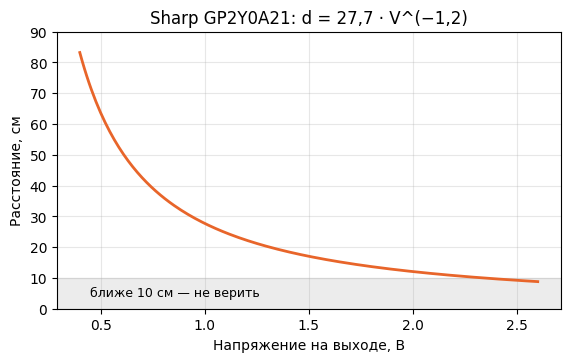

In [2]:
import numpy as np
import matplotlib.pyplot as plt

A, B = 27.7, -1.2                     # стартовые коэффициенты, уточните по линейке
volts = np.linspace(0.4, 2.6, 200)
dist = A * volts ** B

plt.figure(figsize=(6.5, 3.6))
plt.plot(volts, dist, color="#E8652A", lw=2)
plt.axhspan(0, 10, color="grey", alpha=0.15)
plt.text(0.45, 4, "ближе 10 см — не верить", fontsize=9)
plt.xlabel("Напряжение на выходе, В")
plt.ylabel("Расстояние, см")
plt.title("Sharp GP2Y0A21: d = 27,7 · V^(−1,2)")
plt.ylim(0, 90)
plt.grid(alpha=0.3)
plt.show()

```cpp
const int SHARP_PIN = A4;

float readSharpCm() {
  long sum = 0;
  for (int i = 0; i < 5; i++) sum += analogRead(SHARP_PIN);
  float volts = sum / 5.0 * 5.0 / 1023.0;
  if (volts < 0.35) return 80;      // дальше рабочего диапазона
  return 27.7 * pow(volts, -1.2);   // приближение, уточните по линейке
}
```

Для точности запишите напряжение на 10, 20, 40 и 60 см по линейке и подгоните коэффициенты.

### HC-SR04

Датчик издаёт короткий ультразвуковой импульс и ждёт эха. Импульс запускается сигналом HIGH на Trig длиной 10 мкс. Потом Echo держит HIGH столько, сколько звук летел туда и обратно. Звук проходит 1 см туда и обратно примерно за 58 мкс: **расстояние в см = время в мкс / 58.**

- У датчика четыре вывода, в трипиновый разъём Troyka он не встаёт. Подключайте проводами: Vcc — 5 В, GND — GND, Trig — D11, Echo — A5.
- Мягкие и наклонные поверхности отражают звук плохо: датчик может не увидеть ткань или стену под углом.
- Опрашивайте не чаще раза в 50–60 мс. При слишком частом опросе (чаще раза в 5 мс) датчик ловит старое эхо.

> **Важно для езды по линии:** `pulseIn()` останавливает программу, пока ждёт эхо. Без таймаута ожидание длится до секунды, и всё это время робот едет вслепую. Всегда ставьте таймаут.

```cpp
const int TRIG = 11, ECHO = A5;

// в setup(): pinMode(TRIG, OUTPUT); pinMode(ECHO, INPUT);
float readUltrasonicCm() {
  digitalWrite(TRIG, LOW);  delayMicroseconds(2);
  digitalWrite(TRIG, HIGH); delayMicroseconds(10);
  digitalWrite(TRIG, LOW);
  unsigned long t = pulseIn(ECHO, HIGH, 12000);  // ждём не дольше 12 мс ≈ 2 м
  if (t == 0) return -1;                          // эха нет
  return t / 58.0;
}
```

**Проверка обоих:** поставьте книгу на 20 и 50 см по линейке — показания должны совпадать в пределах пары сантиметров.

## 11. Карта пинов

У всех команд одна раскладка. Тогда примеры из пайбука работают без правок, а код одной команды запускается на роботе другой. Менять её — только с руководителем.

| Пин | Что подключено | Почему именно сюда |
| --- | --- | --- |
| D0, D1 | USB / Serial | Не занимать: иначе не зальётся скетч |
| D2 | Энкодер левый, канал A (жёлтый) | Пин с прерыванием |
| D3 | Энкодер правый, канал A (жёлтый) | Пин с прерыванием |
| D4 | Направление левого мотора | Занят Motor Shield |
| D5 | Скорость левого мотора (ШИМ) | Занят Motor Shield |
| D6 | Скорость правого мотора (ШИМ) | Занят Motor Shield |
| D7 | Направление правого мотора | Занят Motor Shield |
| D8 | Энкодер левый, канал B (зелёный) | Любой свободный цифровой |
| D9 | Серва подъёма MG996R, сигнал | Питание сервы — от DC-DC |
| D10 | Серва губок SG90, сигнал | Питание сервы — от DC-DC |
| D11 | HC-SR04, Trig | |
| D12 | Энкодер правый, канал B (зелёный) | Любой свободный цифровой |
| D13 | Свободен | Светодиод L, удобен для отладки |
| A0 | Датчик линии левый | Перемычки измерения тока на Motor Shield сняты |
| A1 | Датчик линии правый | То же |
| A2, A3 | Свободны | Запас под дополнительные датчики линии |
| A4 | Sharp GP2Y0A21 | Аналоговый вход |
| A5 | HC-SR04, Echo | Работает как цифровой вход |

Питание датчиков и энкодеров — с линий V (5 В) и G на Troyka Shield.

Начало скетча для копирования:

```cpp
// Карта пинов Школы мобильных роботов
const int L_ENC_A = 2,  R_ENC_A = 3;    // прерывания
const int L_DIR   = 4,  L_PWM   = 5;    // Motor Shield, M1 — левый
const int R_PWM   = 6,  R_DIR   = 7;    // Motor Shield, M2 — правый
const int L_ENC_B = 8,  R_ENC_B = 12;
const int LIFT_PIN = 9, GRIP_PIN = 10;  // сервы: подъём MG996R, губки SG90
const int US_TRIG = 11, US_ECHO = A5;   // HC-SR04
const int SHARP_PIN = A4;
const int LINE_L = A0,  LINE_R = A1;    // датчики линии
```

## 12. Первое включение

Включайте робота по частям, в этом порядке. Так неисправность находится на том шаге, где она появилась, и ничего не сгорает.

**До подачи питания**

- [ ] Нет оголённых проводов, ничего не задевает колёса.
- [ ] Аккумуляторы стоят по маркировке кассеты, выключатель в положении «выкл».
- [ ] Шилды сидят ровно: все ножки в своих гнёздах, ничего не сдвинуто на ряд.
- [ ] На Motor Shield стоит джампер объединения питания, перемычки измерения тока сняты.
- [ ] Сервы отключены от DC-DC.

**Питание**

- [ ] Включите выключатель. Мультиметр на клеммнике Motor Shield показывает 9,6–12,6 В, горит светодиод PWR.
- [ ] На выходе DC-DC 5,0 В ± 0,2 В.
- [ ] Контроллер включился без USB: горит светодиод ON. Выключите питание.

**Контроллер и моторы**

- [ ] По USB залит Blink, светодиод L мигает.
- [ ] Робот на подставке, колёса в воздухе. Тест моторов из раздела 6 с включённой батареей: оба колеса вперёд, назад, в разные стороны. Направление исправлено флагом `INVERT`.
- [ ] Энкодеры: оборот колеса рукой ≈ 495 тиков, при движении вперёд оба счётчика растут.
- [ ] Записана мёртвая зона каждого мотора на полу.

**Датчики и захват**

- [ ] Датчики линии: чёткие горбы в Serial Plotter, записаны значения на белом и чёрном.
- [ ] Sharp и HC-SR04: показания на 20 и 50 см совпадают с линейкой.
- [ ] Сервы подключены к DC-DC, сигнал на D9 и D10. Калибровка сначала без качалок, четыре угла записаны.
- [ ] Только теперь робот ставится на пол.

## 13. Неисправности

Ищите симптом в левой колонке. Не нашли — пройдите чек-лист «Первое включение» заново и напишите в чат, на каком шаге остановились.

| Симптом | Вероятная причина | Что делать |
| --- | --- | --- |
| Скетч не заливается | Не тот порт или плата, заняты D0/D1, открыт другой монитор порта | Выбрать «Arduino Uno» и правильный порт, освободить D0/D1, закрыть лишние окна |
| Робот работает от USB, но не от батареи | Нет джампера объединения питания, выключатель, сели аккумуляторы | Проверить джампер, измерить напряжение на клеммнике |
| Светодиоды DIR/EN горят, мотор стоит | Нет силового питания или провод мотора не зажат | Горит ли PWR; пережать красный и белый в клеммнике |
| Мотор гудит, но не крутится | ШИМ ниже мёртвой зоны | Поднять минимальную скорость в коде |
| Одно колесо крутится назад | Моторы стоят зеркально | Флаг `INVERT` для этого мотора |
| Робота уводит в сторону на прямой | Разброс моторов, ослаб винт ступицы, слетело резиновое кольцо | Проверить колёса; выравнивать скорости по энкодерам |
| Счётчик энкодера стоит на 0 | Нет питания на синем проводе, канал A не на D2/D3 | Проверить 5 В на синем, жёлтый — на D2/D3 |
| Счётчик дёргается туда-сюда | Перепутаны каналы A и B или плохой контакт | Перепроверить жёлтый и зелёный |
| Датчик линии показывает одно и то же | Шлейф развёрнут, слишком высоко или закручен подстроечник | Жёлтый к S, опустить до 3–6 мм, перенастроить |
| Робот не разворачивается в конце линии | Линия между датчиками: конец линии выглядит как ровная езда | Метка, энкодеры или датчик расстояния (раздел 9) |
| Контроллер перезагружается, когда двигается серва | Серва питается от 5V контроллера | Питание сервы — от DC-DC |
| Серва дёргается или не слушается | Нет общей земли | Соединить GND DC-DC и контроллера |
| Серва гудит и греется | Упирается в механический упор | Сразу выключить, перекалибровать углы |
| При развороте захват цепляет препятствия | Захват далеко впереди оси колёс | Поднимать захват перед разворотом |
| Робот на секунду «слепнет» и сходит с линии | `delay()` или `pulseIn()` без таймаута в `loop()` | Убрать `delay()`, ставить таймаут |
| Робот заметно замедлился | Сели аккумуляторы | Измерить: ниже 9,6 В — на зарядку |
| Что-то греется или пахнет | Короткое замыкание или переполюсовка | **Сразу выключить** и позвать руководителя |